In [1]:
import re
import os
import pathlib
import datetime
import subprocess
import polars as pl
from IPython.display import display
from IPython.display import Image

pl.Config.set_fmt_str_lengths(200)
os.environ["POLARS_MAX_THREADS"] = "16"

In [2]:
execute_date = datetime.datetime.now().strftime("%y%m%d")  # noqa: DTZ005
print(f"Execute Date: {execute_date}")

Execute Date: 261006


&nbsp;

&nbsp;

## Survey: ENST00000607414.3 - FCHS_131348 pair

### BackGround

- [../06_gene_research/06_5_down5p_enhancer_derived_lncRNA.ipynb](../06_gene_research/06_5_down5p_enhancer_derived_lncRNA.ipynb) で、通常条件時 (ストレスを加えていない条件) に HSP90AA1 との enhancer-promoter interaction があることが判明したため、深堀り

&nbsp;

In [4]:
down5p_fantabio = pl.read_parquet(
    "../../out/fantabio/parquet_file/bottom5p_transcript_fantabio_v261001.parquet"
)

pl.Config.set_tbl_rows(2)
display(down5p_fantabio)

transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000834029.1""",69,117,220,-48,47,56,148,-9,"""EXO5-DT""","""HGNC:55647""","""lncRNA""","""ENSG00000238287.2""","[""basic"", ""Ensembl_canonical"", … ""TAGENE""]","""-""",4,"""URS0002A1647B""","""ENSEMBL_GENCODE""",null,"""havana_homo_sapiens""","[""CLS3 project""]",1,"""FCHS_11684""","""chr1""",40508315,"""40508650""","""cp5@EXO5""","[""ENST00000925740.1""]","""0""",-63,"[{""EH38E2805480"",""PLS""}]","[{""ZNF687"",3399,[{""SRX10478566"",3399}, {""SRX10478565"",2503}]}, {""TCF7"",2966,[{""SRX10774913"",2966}, {""SRX10774914"",2622}]}, … {""NFATC1"",515,[{""SRX335071"",515}]}]","[{""HS_00004908"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}, {""HS_00004909"",""Foreskin Melanocyte Primary Cells skin01"",""Prepuce"",""Skin"",""SVM""}, … {""HS_00004912"",""Small Intestine"",""Small intestine"",""Intestine"",""SVM""}]","[{""hg19::chr1:40974317..40974346,-;hg_11928.1"",""hg_11928.1""}]",null,0.952663,"""ELA""","""255,202,74""","""yellow"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000549545.1""",11,265,130,-254,8,174,69,-166,"""COQ10A""","""HGNC:26515""","""retained_intron""","""ENSG00000135469.15""",[],"""+""",0,null,null,null,"""ensembl_havana_gene_homo_sapiens""",null,0,"""FCHS_96252""","""chr12""",56268140,"""56268446""","""cp6@COQ10A""","[""ENST00000549545.1""]","""-23""",-23,"[{""EH38E4064794"",""pELS""}]",null,"[{""HS_00173371"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_02053667"",""Thyroid Gland"",""Thyroid gland"",""Others"",""gkmSVM""}]",null,null,-0.368421,"""ELA""","""255,202,74""","""yellow"""


In [ ]:
# この transcript には、いくつかの シスエレメントが紐づいている
ENST00000607414_3 = down5p_fantabio.filter(
    pl.col("transcript_id") == "ENST00000607414.3"
)

pl.Config.set_tbl_rows(4)
display(ENST00000607414_3)

transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000607414.3""",72,152,182,-80,36,96,119,-60,null,null,"""lncRNA""","""ENSG00000271780.3""","[""TAGENE""]","""+""",1,"""URS0002A15F45""","""ENSEMBL_GENCODE""",null,"""havana_homo_sapiens""","[""Assembled from PacBio CLS3 reads"", ""CLS3 project""]",2,"""FCHS_131346""","""chr14""",101947555,"""101947875""","""FCHS_131346""","[""ENST00000607414.3""]","""250""",250,"[{""EH38E3117699"",""pELS""}, {""EH38E4115838"",""pELS""}]","[{""ATF4"",3403,[{""SRX10900663"",3403}, {""SRX10900664"",3358}, … {""SRX10212067"",2874}]}, {""SUPT5H"",2462,[{""SRX2314263"",2462}]}, … {""GATA1"",514,[{""SRX4172745"",514}, {""SRX4172743"",507}]}]","[{""HS_00200011"",""Fetal Intestine Small"",""Small intestine"",""Intestine"",""SVM""}, {""HS_00200012"",""HeLa-S3"",""Cervix"",""Others"",""SVM""}, … {""HS_00200015"",""HMEC Mammary Epithelial Primary Cells"",""Mammary gland"",""Breast"",""SVM""}]","[{""hg38::chr14:101947866..101947868,+;hg_225869.1"",""hg_225869.1""}]",null,0.95,"""ELA""","""255,202,74""","""yellow"""
"""ENST00000607414.3""",72,152,182,-80,36,96,119,-60,null,null,"""lncRNA""","""ENSG00000271780.3""","[""TAGENE""]","""+""",1,"""URS0002A15F45""","""ENSEMBL_GENCODE""",null,"""havana_homo_sapiens""","[""Assembled from PacBio CLS3 reads"", ""CLS3 project""]",2,"""FCHS_131347""","""chr14""",101947839,"""101947906""","""FCHS_131347""","[""ENST00000607414.3""]","""219""",219,"[{""EH38E4115838"",""pELS""}]","[{""CEBPB"",3783,[{""SRX9029207"",3783}, {""SRX9029206"",3645}, … {""SRX2423913"",1676}]}, {""CREB1"",3611,[{""SRX1212238"",3611}, {""SRX1212234"",3227}, … {""SRX359882"",924}]}, … {""ARID2"",508,[{""SRX4473673"",508}]}]","[{""HS_00200011"",""Fetal Intestine Small"",""Small intestine"",""Intestine"",""SVM""}, {""HS_00200012"",""HeLa-S3"",""Cervix"",""Others"",""SVM""}, … {""HS_00200015"",""HMEC Mammary Epithelial Primary Cells"",""Mammary gland"",""Breast"",""SVM""}]","[{""hg38::chr14:101947866..101947868,+;hg_225869.1"",""hg_225869.1""}]","[{[""chr14:101947889-101948858""]}]",1.0,"""ELA""","""255,202,74""","""yellow"""
"""ENST00000607414.3""",72,152,182,-80,36,96,119,-60,null,null,"""lncRNA""","""ENSG00000271780.3""","[""TAGENE""]","""+""",1,"""URS0002A15F45""","""ENSEMBL_GENCODE""",null,"""havana_homo_sapiens""","[""Assembled from PacBio CLS3 reads"", ""CLS3 project""]",2,"""FCHS_131348""","""chr14""",101947932,"""101948557""","""FCHS_131348""","[""ENST00000690320.2"", ""ENST00000607414.3"", … ""ENST00000716867.1""]","""0""",0,"[{""EH38E1743601"",""pELS""}, {""EH38E3117702"",""PLS""}]","[{""REST"",4855,[{""SRX9599295"",4855}, {""SRX9599293"",4825}, … {""SRX3323031"",510}]}, {""GFP"",4363,[{""SRX1457801"",4363}, {""SRX1457804"",2575}, … {""SRX21810589"",511}]}, … {""FOXP1"",500,[{""SRX5442198"",500}]}]","[{""HS_00200011"",""Fetal Intestine Small"",""Small intestine"",""Intestine"",""SVM""}, {""HS_00200012"",""HeLa-S3"",""Cervix"",""Others"",""SVM""}, … {""HS_00200015"",""HMEC Mammary Epithelial Primary Cells"",""Mammary gland"",""Breast"",""SVM""}]","[{""hg19::chr14:102414353..102414415,-;hg_144989.1"",""hg_144989.1""}, {""hg19::chr14:102414651..102414721,+;hg_141632.1"",""hg_141632.1""}]","[{[""chr14:101947889-101948858""]}]",0.616237,"""PLA""","""153,0,0""","""dark_re

&nbsp;

&nbsp;

## ENCODE-rE2G data

In [16]:
ENST00000607414_3_e_derived_lncRNA_down_up = pl.read_parquet(
    "../../out/transcript_classification/enhancer_derived_lncRNA/down5p_enhancer_derived_lncRNA_v261003_DOWN_UP.parquet"
).filter(
    (pl.col("e_transcript_id") == "ENST00000607414.3")
    # & (pl.col("t_transcript_type") == "protein_coding") # 標的となる promoter の近傍にある transcript は、protein coding のみとする
    & (pl.col("re2g_dataset_count") >= 1000) # シスエレメントは、1000 データセット以上で相互作用が検出されたもののみとする

)

pl.Config.set_tbl_rows(100)
display(ENST00000607414_3_e_derived_lncRNA_down_up)

cre_id,cre_name,fantabio_cre_class,target_cre_id,target_cre_name,target_fantabio_cre_class,re2g_dataset,re2g_dataset_count,enhancer_cre_overlap_frac_of_fantabio_cre,enhancer_cre_overlap_frac_of_fantabio_cre_min,enhancer_cre_overlap_frac_of_fantabio_cre_max,enhancer_cre_overlap_frac_of_fantabio_cre_mean,ENCODE-rE2G.Score,ENCODE-rE2G.Score_min,ENCODE-rE2G.Score_max,ENCODE-rE2G.Score_mean,e_transcript_id,e_HN2,e_transcript_type,e_gene_id,e_gene_symbol,e_strand,e_RNACentral_ID,e_annotation_remarks,e_tags,t_transcript_id,t_HN2,t_transcript_type,t_gene_id,t_gene_symbol,t_strand,t_RNACentral_ID,t_annotation_remarks,t_tags
str,str,str,str,str,str,list[cat],u32,list[f64],f64,f64,f64,list[f64],f64,f64,f64,str,i64,str,str,str,str,str,list[str],list[str],str,i64,str,str,str,str,str,list[str],list[str]
"""FCHS_131348""","""FCHS_131348""","""PLA""","""FCHS_131357""","""cp17@DYNC1H1""","""PLA""","[""ENCSR000MZA_ENCFF654AMU"", ""ENCSR002YWN_ENCFF435DPV"", … ""ENCSR999YQC_ENCFF625FFH""]",1457,"[0.798722, 0.747604, … 0.948882]",0.715655,1.0,0.847006,"[0.741714, 0.640199, … 0.870967]",0.261641,0.970485,0.81886,"""ENST00000607414.3""",-80,"""lncRNA""","""ENSG00000271780.3""",null,"""+""","""URS0002A15F45""","[""Assembled from PacBio CLS3 reads"", ""CLS3 project""]","[""TAGENE""]","""ENST00000680313.1""",256,"""nonsense_mediated_decay""","""ENSG00000197102.15""","""DYNC1H1""","""+""",null,"[""inferred transcript model"", ""RNA-Seq supported only""]","[""inferred_transcript_model"", ""RNA_Seq_supported_only""]"
"""FCHS_131348""","""FCHS_131348""","""PLA""","""FCHS_131357""","""cp17@DYNC1H1""","""PLA""","[""ENCSR000MZA_ENCFF654AMU"", ""ENCSR002YWN_ENCFF435DPV"", … ""ENCSR999YQC_ENCFF625FFH""]",1457,"[0.798722, 0.747604, … 0.948882]",0.715655,1.0,0.847006,"[0.741714, 0.640199, … 0.870967]",0.261641,0.970485,0.81886,"""ENST00000607414.3""",-80,"""lncRNA""","""ENSG00000271780.3""",null,"""+""","""URS0002A15F45""","[""Assembled from PacBio CLS3 reads"", ""CLS3 project""]","[""TAGENE""]","""ENST00000645039.2""",89,"""nonsense_mediated_decay""","""ENSG00000197102.15""","""DYNC1H1""","""+""",null,"[""RNA-Seq supported only"", ""inferred transcript model""]","[""RNA_Seq_supported_only"", ""inferred_transcript_model""]"
"""FCHS_131348""","""FCHS_131348""","""PLA""","""FCHS_131357""","""cp17@DYNC1H1""","""PLA""","[""ENCSR000MZA_ENCFF654AMU"", ""ENCSR002YWN_ENCFF435DPV"", … ""ENCSR999YQC_ENCFF625FFH""]",1457,"[0.798722, 0.747604, … 0.948882]",0.715655,1.0,0.847006,"[0.741714, 0.640199, … 0.870967]",0.261641,0.970485,0.81886,"""ENST00000607414.3""",-80,"""lncRNA""","""ENSG00000271780.3""",null,"""+""","""URS0002A15F45""","[""Assembled from PacBio CLS3 reads"", ""CLS3 project""]","[""TAGENE""]","""ENST00000681123.1""",83,"""nonsense_mediated_decay""","""ENSG00000197102.15""","""DYNC1H1""","""+""",null,"[""inferred transcript model"", ""RNA-Seq supported only""]","[""inferred_transcript_model"", ""RNA_Seq_supported_only""]"
"""FCHS_131348""","""FCHS_131348""","""PLA""","""FCHS_131357""","""cp17@DYNC1H1""","""PLA""","[""ENCSR000MZA_ENCFF654AMU"", ""ENCSR002YWN_ENCFF435DPV"", … ""ENCSR999YQC_ENCFF625FFH""]",1457,"[0.798722, 0.747604, … 0.948882]",0.715655,1.0,0.847006,"[0.741714, 0.640199, … 0.870967]",0.261641,0.970485,0.81886,"""ENST00000607414.3""",-80,"""lncRNA""","""ENSG00000271780.3""",null,"""+""","""URS0002A15F45""","[""Assembled from PacBio CLS3 reads"", ""CLS3 project""]","[""TAGENE""]","""ENST00000681574.1""",73,"""protein_coding""","""ENSG00000197102.15""","""DYNC1H1""","""+""",null,"[""retained intron final"", ""inferred transcript model"", ""RNA-Seq supported partial""]","[""retained_intron_final"", ""inferred_transcript_model"", … ""GENCODE_Primary""]"
"""FCHS_131348""","""FCHS_131348""","""PLA""","""FCHS_131357""","""cp17@DYNC1H1""","""PLA""","[""ENCSR000MZA_ENCFF654AMU"", ""ENCSR002YWN_ENCFF435DPV"", … ""ENCSR999YQC_ENCFF625FFH""]",1457,"[0.798722, 0.747604, … 0.948882]",0.715655,1.0,0.847006,"[0.741714, 0.640199, … 0.870967]",0.261641,0.970485,0.8

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Visualization

- `pyGenometracks` で可視化 ([../05_ENCODE_rE2G/03_encode_re2g_check_positive_control_hs.ipynb](../05_ENCODE_rE2G/03_encode_re2g_check_positive_control_hs.ipynb) と同じ構成)
- 領域: [UCSC hg38 chr14:101,655,084-102,281,083](https://genome.ucsc.edu/cgi-bin/hgTracks?db=hg38&position=chr14%3A101655084%2D102281083)
- トラックは上から ENCODE-rE2G arcs (`FCHS_131348` → 標的 CRE) / fanta.bio CRE / transcript (enhancer-derived lncRNA と標的 transcript)

In [26]:
# Plot window: UCSC chr14:101,655,084-102,281,083 (GRCh38)
# https://genome.ucsc.edu/cgi-bin/hgTracks?db=hg38&position=chr14%3A101655084%2D102281083

REGION_CHROM = "chr14"
REGION_START = 101_750_000
REGION_END = 102_150_000

# REGION_START = 101_655_084
# REGION_END = 102_281_083

repo_root = pathlib.Path("../..").resolve()
gtf_full = repo_root / "Data/Database/GENCODE_v49/gencode.v49.chr_patch_hapl_scaff.annotation.gtf"
cre_full = repo_root / "Data/Database/fantabio/human-CREv1.2.1.hg38.cre-peaks.bed"
out_dir = (
    repo_root
    / "out/transcript_classification/pygenometracks"
    / f"ENST00000607414_FCHS_131348_{REGION_CHROM}_{REGION_START}_{REGION_END}"
)
out_dir.mkdir(parents=True, exist_ok=True)
print(out_dir)

/workspaces/HS_human_ncRNA/out/transcript_classification/pygenometracks/ENST00000607414_FCHS_131348_chr14_101750000_102150000


In [27]:
# Enhancer-promoter arcs (one arc per CRE pair; rows are duplicated per target transcript).
ep_pairs = ENST00000607414_3_e_derived_lncRNA_down_up.select(
    "cre_id", "target_cre_id", "target_cre_name", "ENCODE-rE2G.Score_mean", "re2g_dataset_count"
).unique(subset=["cre_id", "target_cre_id"], maintain_order=True)

cre_ids = pl.concat(
    [
        ep_pairs.select("cre_id"),
        ep_pairs.select(pl.col("target_cre_id").alias("cre_id")),
    ]
).unique(maintain_order=True)

# fanta.bio BED has 11 columns; pyGenomeTracks reads itemRgb only up to BED9.
# Column 4 is replaced by cre_name (e.g. cp4@HSP90AA1) so the label shows the gene.
cre_keep = pl.read_csv(
    cre_full,
    separator="\t",
    has_header=False,
    new_columns=[
        "chrom", "start", "end", "cre_id", "score", "strand",
        "thick_start", "thick_end", "item_rgb", "cre_name", "annot",
    ],
).join(cre_ids, on="cre_id", how="inner")

cre_bed9 = out_dir / "FCHS_131348_cre.bed9.bed"
cre_keep.select(
    "chrom", "start", "end", "cre_name", "score", "strand",
    "thick_start", "thick_end", "item_rgb",
).write_csv(cre_bed9, separator="\t", include_header=False)

coords = cre_keep.select("cre_id", "chrom", "start", "end")
links = (
    ep_pairs.join(
        coords.rename({"chrom": "chrom1", "start": "start1", "end": "end1"}),
        on="cre_id",
        how="inner",
    ).join(
        coords.rename(
            {
                "cre_id": "target_cre_id",
                "chrom": "chrom2",
                "start": "start2",
                "end": "end2",
            }
        ),
        on="target_cre_id",
        how="inner",
    )
).select(
    "chrom1", "start1", "end1", "chrom2", "start2", "end2",
    pl.col("ENCODE-rE2G.Score_mean"),
)
re2g_links = out_dir / "FCHS_131348_re2g.links"
links.write_csv(re2g_links, separator="\t", include_header=False)

print(f"CRE intervals: {cre_keep.height}")
print(f"arcs: {links.height}")
display(ep_pairs)
display(links)

CRE intervals: 4
arcs: 3


cre_id,target_cre_id,target_cre_name,ENCODE-rE2G.Score_mean,re2g_dataset_count
str,str,str,f64,u32
"""FCHS_131348""","""FCHS_131357""","""cp17@DYNC1H1""",0.81886,1457
"""FCHS_131348""","""FCHS_131307""","""cp12@PPP2R5C""",0.818355,1443
"""FCHS_131348""","""FCHS_131439""","""cp4@HSP90AA1""",0.419359,1365


chrom1,start1,end1,chrom2,start2,end2,ENCODE-rE2G.Score_mean
str,i64,i64,str,i64,i64,f64
"""chr14""",101947931,101948557,"""chr14""",101809594,101810063,0.818355
"""chr14""",101947931,101948557,"""chr14""",101964185,101964772,0.81886
"""chr14""",101947931,101948557,"""chr14""",102086848,102087577,0.419359


In [28]:
# Full transcript models for the enhancer-derived lncRNA and the target transcripts.
from pygenometracks.readGtf import ReadGtf

tx_info = pl.concat(
    [
        ENST00000607414_3_e_derived_lncRNA_down_up.select(
            pl.col("e_transcript_id").alias("transcript_id"),
            pl.lit("enhancer-derived lncRNA").alias("group"),
        ),
        ENST00000607414_3_e_derived_lncRNA_down_up.select(
            pl.col("t_transcript_id").alias("transcript_id"),
            pl.col("t_gene_symbol").alias("group"),
        ),
    ]
).unique(subset="transcript_id", maintain_order=True)

# A gtf track has one color, so convert to BED12 with itemRgb per group.
GROUP_RGB = {
    "enhancer-derived lncRNA": "230,120,0",
    "DYNC1H1": "0,0,139",
    "PPP2R5C": "0,100,0",
    "HSP90AA1": "128,0,128",
}
tx_group = dict(zip(tx_info["transcript_id"], tx_info["group"]))

# BED12 blocks must span the whole transcript, so pull full models from the GTF.
gtf_header = subprocess.run(
    ["grep", "^#", str(gtf_full)],
    check=True,
    capture_output=True,
    text=True,
)
tx_gtf_full = out_dir / "ENST00000607414_FCHS_131348_transcripts.full.gtf"
tx_patterns = "".join(f'transcript_id "{tx_id}";\n' for tx_id in sorted(tx_group))
tx_full_hits = subprocess.run(
    ["grep", "-F", "-f", "-", str(gtf_full)],
    input=tx_patterns,
    check=True,
    capture_output=True,
    text=True,
)
tx_gtf_full.write_text(gtf_header.stdout + tx_full_hits.stdout)

tx_bed12 = out_dir / "ENST00000607414_FCHS_131348_transcripts.bed12.bed"
tx_found = set()
with tx_bed12.open("w") as handle_out:
    for tx in ReadGtf(str(tx_gtf_full), prefered_name="transcript_id", merge_transcripts=False):
        group = tx_group[tx.name]
        tx_found.add(tx.name)
        label = tx.name if group == "enhancer-derived lncRNA" else f"{tx.name} ({group})"
        handle_out.write(
            "\t".join(
                map(
                    str,
                    [
                        tx.chromosome, tx.start, tx.end, label, tx.score, tx.strand,
                        tx.thick_start, tx.thick_end, GROUP_RGB[group], tx.block_count,
                        ",".join(map(str, tx.block_sizes)),
                        ",".join(map(str, tx.block_starts)),
                    ],
                )
            )
            + "\n"
        )

print(f"transcripts in dataframe: {len(tx_group)}, written to BED12: {len(tx_found)}")
display(tx_info.group_by("group", maintain_order=True).len())

transcripts in dataframe: 17, written to BED12: 17


group,len
str,u32
"""enhancer-derived lncRNA""",1
"""DYNC1H1""",5
"""PPP2R5C""",1
"""HSP90AA1""",10


INFO:pygenometracks.tracksClass:initialize 1. [spacer]
INFO:pygenometracks.tracksClass:initialize 2. [x-axis]
INFO:pygenometracks.tracksClass:initialize 3. [spacer]
INFO:pygenometracks.tracksClass:initialize 4. [rE2G arcs]
100%|██████████| 3/3 [00:00<00:00, 31775.03it/s]
INFO:pygenometracks.tracksClass:initialize 5. [spacer]
INFO:pygenometracks.tracksClass:initialize 6. [fanta CRE]
100%|██████████| 4/4 [00:00<00:00, 48489.06it/s]
INFO:pygenometracks.tracksClass:initialize 7. [spacer]
INFO:pygenometracks.tracksClass:initialize 8. [transcripts]
100%|██████████| 17/17 [00:00<00:00, 51894.59it/s]
INFO:pygenometracks.tracksClass:time initializing track(s):
INFO:pygenometracks.tracksClass:0.007691621780395508
DEBUG:pygenometracks.tracksClass:Figure size in cm is 30.0 x 14.627659574468085. Dpi is set to 150

INFO:pygenometracks.tracksClass:plotting 1. [spacer]
INFO:pygenometracks.tracksClass:plotting 2. [x-axis]
INFO:pygenometracks.tracksClass:plotting 3. [spacer]
INFO:pygenometracks.tracksCl

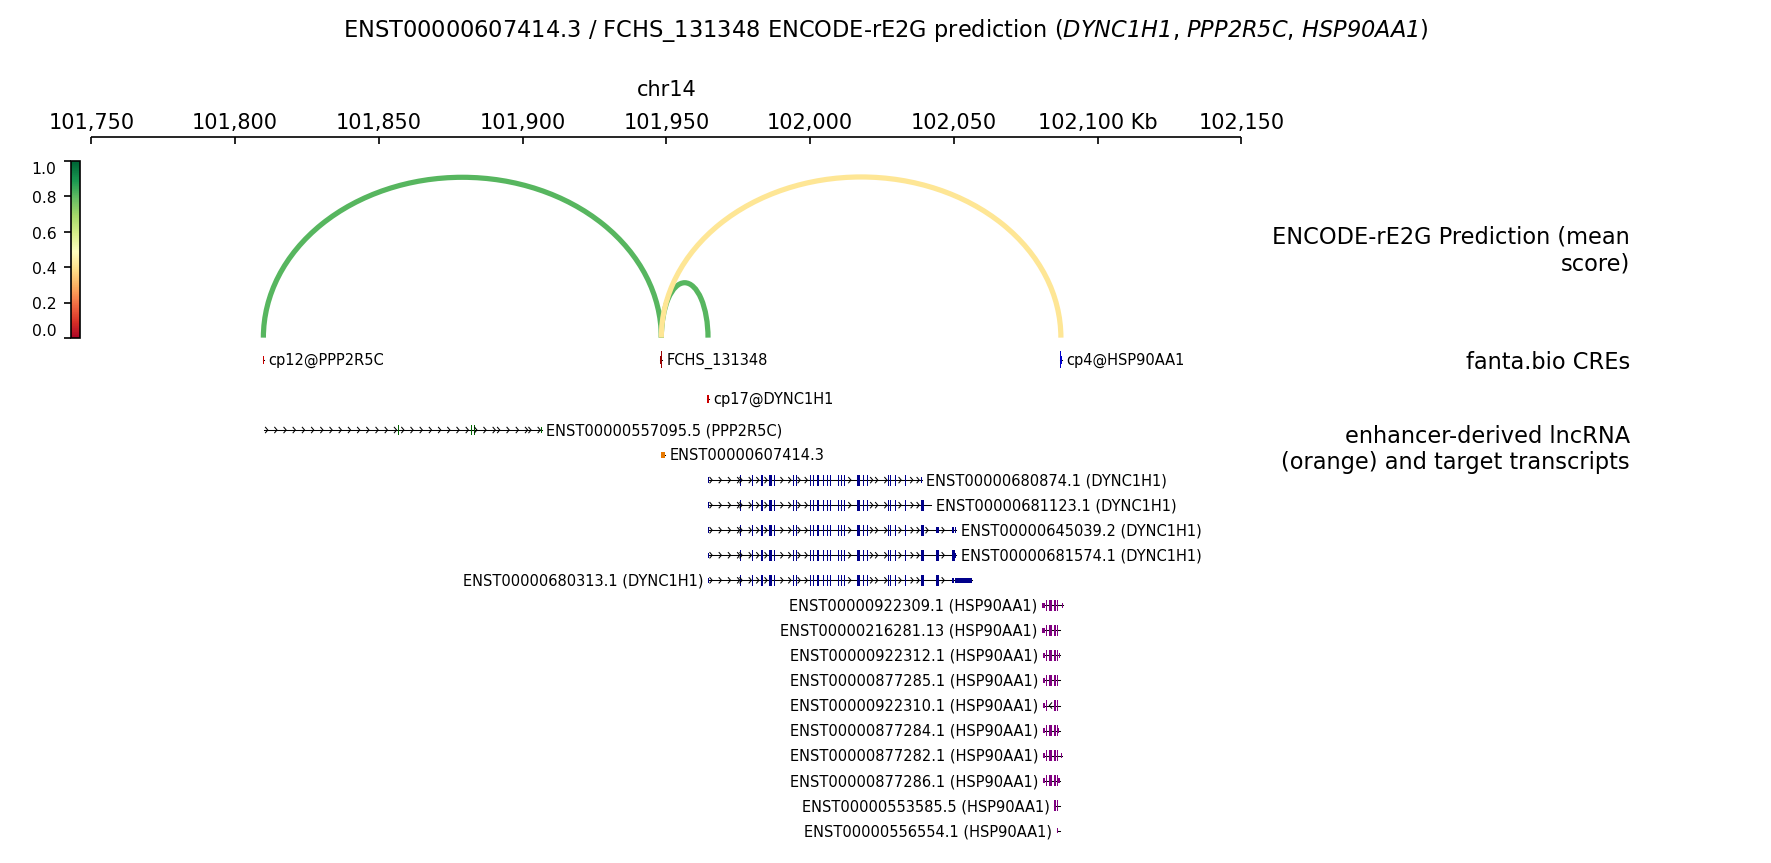

In [29]:
# Arcs on top, CRE anchors in the middle, transcript models at the bottom.
tracks_ini = out_dir / "ENST00000607414_FCHS_131348_tracks.ini"
figure_png = out_dir / "ENST00000607414_FCHS_131348_re2g.png"
tracks_ini.write_text(
    f"""\
[spacer]
height = 0.9

[x-axis]
where = top
fontsize = 10

[spacer]
height = 0.15

[rE2G arcs]
file = {re2g_links.name}
title = ENCODE-rE2G Prediction (mean score)
file_type = links
links_type = arcs
use_middle = true
height = 3
color = RdYlGn
min_value = 0
max_value = 1
line_width = 2.5
line_style = solid
compact_arcs_level = 1

[spacer]
height = 0.2

[fanta CRE]
file = {cre_bed9.name}
title = fanta.bio CREs
file_type = bed
height = 1.0
color = bed_rgb
border_color = none
labels = true
fontsize = 7
style = UCSC
display = stacked

[spacer]
height = 0.25

[transcripts]
file = {tx_bed12.name}
title = enhancer-derived lncRNA (orange) and target transcripts
file_type = bed
height = 7
color = bed_rgb
labels = true
all_labels_inside = true
fontsize = 7
style = UCSC
display = stacked
"""
)

# Mathtext draws digits with mathtext.rm, so both rm and it must be italic
# for gene symbols in the title to render fully italic.
mplrc = out_dir / "matplotlibrc"
mplrc.write_text(
    "mathtext.fontset : custom\n"
    "mathtext.rm : DejaVu Sans:italic\n"
    "mathtext.it : DejaVu Sans:italic\n"
)

subprocess.run(
    [
        "pyGenomeTracks",
        "--tracks",
        str(tracks_ini),
        "--region",
        f"{REGION_CHROM}:{REGION_START}-{REGION_END}",
        "--width",
        "30",
        "--dpi",
        "150",
        "--trackLabelFraction",
        "0.25",
        "--trackLabelHAlign",
        "right",
        "--outFileName",
        str(figure_png),
        "--title",
        r"ENST00000607414.3 / FCHS_131348 ENCODE-rE2G prediction ($\mathrm{DYNC1H1}$, $\mathrm{PPP2R5C}$, $\mathrm{HSP90AA1}$)",
    ],
    check=True,
    cwd=out_dir,
    env={**os.environ, "MATPLOTLIBRC": str(mplrc)},
)
display(Image(filename=str(figure_png)))